# Pima Indians Diabetes — Classification
Predicting whether a patient has diabetes based on diagnostic medical attributes, using the [Pima Indians Diabetes Dataset](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database).

**Pipeline:** load & explore data → preprocess → train multiple classifiers → evaluate & compare → save the best model.

In [ ]:

import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Data Loading & Exploration

In [ ]:
columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
df = pd.read_csv(url, names=columns)

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset loaded: 768 rows, 9 columns


In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (768, 9)


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Extra exploration.** This dataset encodes missing measurements as `0` for several medical columns where a true zero is biologically impossible
(e.g. `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`). A plain `isnull()` check won't catch these, so let's look for them explicitly,
and check the class balance of the target.

In [ ]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_cols] == 0).sum()
print("Zero values (likely missing data) per column:")
print(zero_counts)

print("\nClass balance (Outcome):")
print(df["Outcome"].value_counts(normalize=True).rename("proportion"))

Zero values (likely missing data) per column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Class balance (Outcome):
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


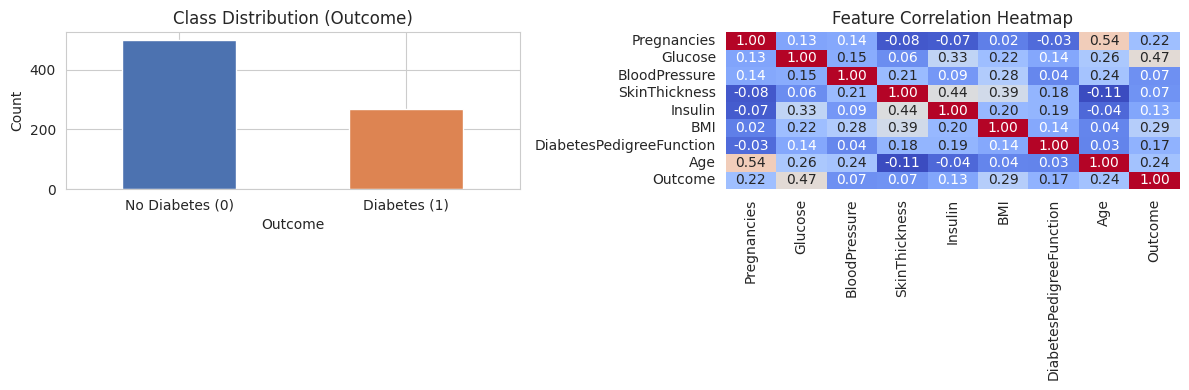

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["Outcome"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Class Distribution (Outcome)")
axes[0].set_xticklabels(["No Diabetes (0)", "Diabetes (1)"], rotation=0)
axes[0].set_ylabel("Count")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], cbar=False)
axes[1].set_title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

## 2. Data Preprocessing

Steps:
1. Replace biologically-impossible zeros in medical columns with `NaN`, then impute with the column median.
2. Separate features (`X`) and target (`y`).
3. Train/test split — 80% training, 20% testing (stratified, so both sets keep the same diabetes/no-diabetes ratio).
4. Scale features with `StandardScaler` (needed for distance/margin-based models like SVM and KNN, and helps Logistic Regression converge).

In [ ]:
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
df_clean[zero_cols] = df_clean[zero_cols].fillna(df_clean[zero_cols].median())

print("Remaining missing values after imputation:", df_clean.isnull().sum().sum())

Remaining missing values after imputation: 0


In [ ]:

X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (614, 8)
Test set: (154, 8)


In [ ]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Model Training

We train **three** classifiers from the suggested list:
- Logistic Regression
- Random Forest
- Support Vector Machine (SVM, with probability estimates enabled for ROC-AUC)

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=200),
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"Trained: {name}")

Trained: Logistic Regression


Trained: Random Forest
Trained: SVM


## 4. Model Evaluation

Evaluate each model on the held-out test set using Accuracy, Precision, Recall, F1, and ROC-AUC.

In [ ]:
results = []
roc_data = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, auc)

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.740260,0.652174,0.555556,0.600000,0.816111
1,Logistic Regression,0.707792,0.600000,0.500000,0.545455,0.812963
2,SVM,0.740260,0.652174,0.555556,0.600000,0.796389


In [ ]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    print(f"\n{'='*50}\n{name}\n{'='*50}")
    print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))


Logistic Regression
              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


Random Forest
              precision    recall  f1-score   support

 No Diabetes       0.78      0.84      0.81       100
    Diabetes       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


SVM
              precision    recall  f1-score   support

 No Diabetes       0.78      0.84      0.81       100
    Diabetes       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74

### ROC Curve — all models compared

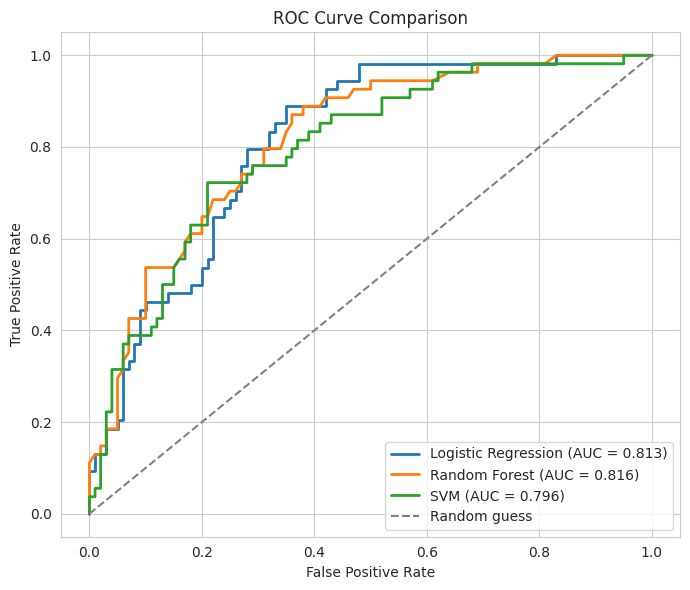

In [ ]:
plt.figure(figsize=(7, 6))

for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Visual comparison of metrics across models

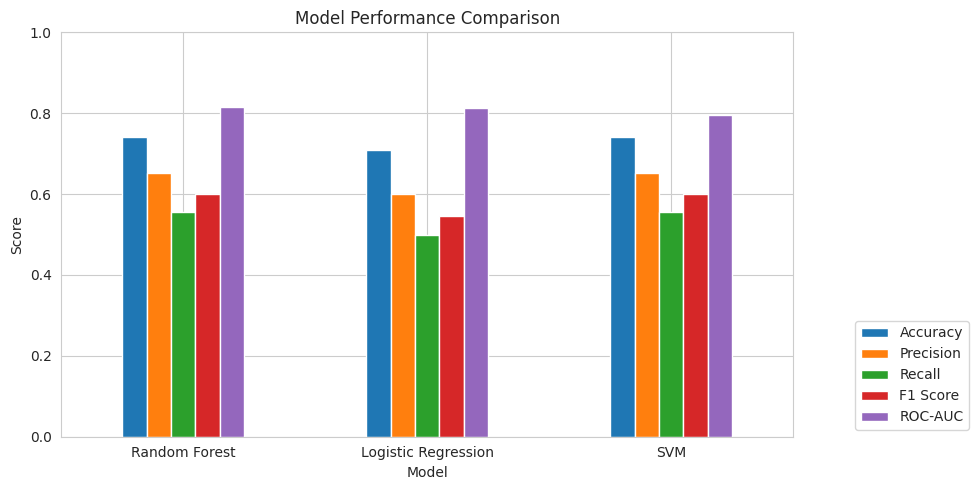

In [ ]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
plot_df = results_df.set_index("Model")[metrics_to_plot]

plot_df.plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right", bbox_to_anchor=(1.25, 0))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Best Model Selection

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print(f"Best performing model (by ROC-AUC): {best_model_name}")
print(results_df.iloc[0])

Best performing model (by ROC-AUC): Random Forest
Model        Random Forest
Accuracy           0.74026
Precision         0.652174
Recall            0.555556
F1 Score               0.6
ROC-AUC           0.816111
Name: 0, dtype: object


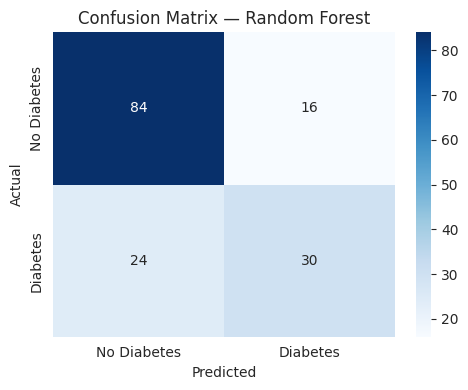

In [ ]:

y_pred_best = best_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 6. Saving the Best Model

In [ ]:
joblib.dump(best_model, "diabetes_model.pkl")
joblib.dump(scaler, "diabetes_scaler.pkl")

print(f"Saved '{best_model_name}' as diabetes_model.pkl")
print("Saved the fitted StandardScaler as diabetes_scaler.pkl")

Saved 'Random Forest' as diabetes_model.pkl
Saved the fitted StandardScaler as diabetes_scaler.pkl


---
### Summary
- Loaded and explored the Pima Indians Diabetes dataset (768 rows, 8 features + target).
- Cleaned biologically-impossible zero values and imputed them with column medians.
- Split data 80/20 (stratified) and scaled features.
- Trained Logistic Regression, Random Forest, and SVM classifiers.
- Evaluated all three on Accuracy, Precision, Recall, F1, and ROC-AUC, and compared them visually via ROC curves and a bar chart.
- Selected the best model by ROC-AUC and saved it (plus the scaler) with `joblib` for reuse.